# Практическая работа №3 (ПР3). Белый ящик: adversarial-робастность замороженной модели

**Задача.** Оценить устойчивость замороженной COVID-модели к **white-box** атакам
(полный доступ к архитектуре, весам и градиентам; пользовательский вход — рентген-снимок
после Resize(224)). Модель не переобучается.

**Угроза-модель (клиническая).** Злоумышленник вносит минимальные преднамеренные
искажения пикселей (L∞-бюджет ε) в момент передачи/сохранения снимка (DICOM → PNG),
чтобы предсказание изменилось: например, «Normal → COVID» (ложная тревога) или
«COVID → Normal» (пропуск диагноза). Пер-пиксельное возмущение масштаба ε ≤ 16/255
визуально незаметно для человека.

**Параметры модели нарушителя (фиксируются до эксперимента, practice_ai.pdf §4.2):**

| Параметр | Значение |
|---|---|
| Knowledge | **white-box** (полный доступ к архитектуре, весам, градиентам) |
| Goal | **untargeted** (добиться любой смены предсказания на неверное; целевые атаки не требуются) |
| Access | gradients (используется CE-loss и её градиенты по входу) |
| Perturbation space | L∞ по пикселям в [0,1]-пространстве после Resize(224) |
| Attack budget | ε ∈ {1, 2, 4, 8, 16}/255; query budget — **N/A (не применимо для white-box)**; число изменённых пикселей — не ограничивается (L∞-бюджет) |
| Validity constraints | все adversarial-примеры клипаются к [0,1] (домен изображения); Validity Rate считается и приводится явно |

*Соответствие требованию PDF:* «без явного описания threat model вывод “модель робастна”
считается некорректным» — threat model зафиксирован выше до результатов. Для white-box
отдельно требуется проверка gradient masking (§4.6): параметры атаки задокументированы
(10 итераций, шаг α = ε/4, 3 случайных перезапуска), а независимый контроль выполнен
сильой атакой AutoAttack/APGD-CE (см. ниже).

**Методы атак (≥2, оба white-box):**

| Метод | Параметры |
|---|---|
| **FGSM** | одноступенчатая, градиент CE по метке |
| **PGD-10** | 10 итераций, α = ε/4, случайный старт Uniform(−ε, ε), 3 перезапуска (best-of-loss) |

- Опциональный CW не требуется (для 2-классовой задачи достаточно FGSM + PGD; CW
  решил не подключать ради экономии времени и затраченных ресурсов — отклонение
  от «по желанию» конспекта не в пользу полноты, но не влияет на выводы).
- **Sanity check:** независимый атакующий *AutoAttack* (реализация torchattacks) при
  ε = 8/255 на том же подмножестве. Полная композиция AutoAttack (standard) включает
  targeted-атаки (APGD-T/FAB-T) и DLR-лоссы, которые для 2-классовой задачи
  математически не определены (DLR использует 3-й и 4-й по величине логиты), поэтому
  применяется ключевой компонент — **APGD-CE** (дающий headline-результаты AutoAttack
  и в multi-class постановке); отклонение задокументировано в ноутбуке и отчёте.

**Сетка ε (бюджет L∞, в единицах [0,1]):** ε ∈ {1, 2, 4, 8, 16}/255 — минимальный шаг
1/255 ≈ 1 ед. из 255 (визуально неотличимо), максимум 16/255 ≈ 6.3% интенсивности.

**Метрики (все с 95% CI):**
- **FR(ε)** (fraud rate = ASR): доля чисто-правильно классифицируемых снимков подмножества,
  для которых adversarial-предсказание стало неверным; Wilson CI;
- **Эффективность текущей модели (robust accuracy):** Acc_rob(ε) — accuracy на
  adversarial-наборе (числитель: чисто-правильные и правильно предсказанные после атаки;
  знаменатель: полный поднабор), Wilson CI;
- **Validity Rate(ε)** = N_valid_adversarial / N_generated_adversarial (все adversarial-
  примеры проверяются на конечность значений и попадание в [0,1]); ожидается 1.000, но
  метрика считается и приводится явно для каждого (атака, ε);
- **Perturbation magnitude:** максимум L∞ (≤ ε по построению) и статистики L₂-нормы δ;
- кривые FR/Acc_rob по ε (вкл. ε=0 = чистые данные), нет структурных сдвигов R-AUC_ε:
  нормированная площадь под кривой Acc_rob по сетке ε с paired bootstrap по объектам
  подмножества (B=2000, процентильный CI);
- **многоразовые seeds:** для стохастической части PGD (случайный старт) помимо основной
  сетки выполняется серия из 3 seeds при ε = 8/255 (проверка устойчивости результата к seed);
- Query count / Median queries to success / B→ASR(B): **N/A для white-box**
  (все три относятся только к black-box постановке);
- for sanity: попарное сравнение PGD и AutoAttack при ε=8/255.

Подмножество атаки: 200 тестовых снимков, стратифицированно 50/50 (COVID/Normal),
детерминированная выборка по seed. Все атаки — в [0,1]-пространстве пикселей с
клипом [0,1] и нормализацией ImageNet внутри обёртки модели (PixelModel).


In [1]:
# Подготовка: модель-обёртка (PixelModel), подмножество 200 снимков, чистые предсказания
import sys, json, time
from pathlib import Path

sys.path.insert(0, r"E:\ML_Projects\Covid")
import common
from common import (SEED, set_seed, build_model, get_splits, DEVICE,
                    MEAN, STD, RESULTS_DIR, FIGURES_DIR, wilson_ci, fmt_ci)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

set_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

repro = common.load_repro()
print("Устройство:", DEVICE.type, "| torch", torch.__version__)

model_base = build_model()
model_base.eval()

MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)

class PixelModel(nn.Module):
    """Принимает изображения в [0,1] (N,3,224,224), нормализует внутри, выдаёт логиты."""
    def __init__(self, base):
        super().__init__()
        self.base = base
    @torch.no_grad()
    def forward_nograd(self, x01):
        return self.base((x01 - MEAN_T) / STD_T)
    def forward(self, x01):
        return self.base((x01 - MEAN_T) / STD_T)

pm = PixelModel(model_base).to(DEVICE).eval()

# --- подмножество атаки: 200 тестовых снимков, 50/50, детерминированно
splits = get_splits()
test = splits["test"]
rng = np.random.default_rng(SEED)
idx_by_cls = {0: [], 1: []}
for i, (_, y) in enumerate(test):
    idx_by_cls[y].append(i)
sub_idx = np.sort(np.concatenate([np.array(rng.choice(v, size=100, replace=False), dtype=int)
                                  for v in idx_by_cls.values()]))
X = np.stack([
    np.asarray(Image.open(test[i][0]).convert("RGB").resize(
        (224, 224), Image.BILINEAR), dtype=np.uint8)
    for i in sub_idx
])
y_sub = np.array([test[i][1] for i in sub_idx])
ids = [Path(test[i][0]).name for i in sub_idx]

X_t = torch.from_numpy(X.astype(np.float32) / 255.0).permute(0, 3, 1, 2).contiguous().to(DEVICE)
y_t = torch.from_numpy(y_sub).to(DEVICE)
print("подмножество:", tuple(X_t.shape), "| COVID:", int((y_sub == 0).sum()),
      "| Normal:", int((y_sub == 1).sum()))

@torch.no_grad()
def batched_preds(x01_t, bs=100):
    out = []
    for i in range(0, len(x01_t), bs):
        log = pm.forward_nograd(x01_t[i:i+bs])
        out.append(log.argmax(1).cpu().numpy())
    return np.concatenate(out)

preds_clean = batched_preds(X_t)
clean_ok = torch.from_numpy((preds_clean == y_sub).astype(np.int64)).to(DEVICE)
M_sub = (preds_clean == y_sub).mean()
lo, hi = wilson_ci(int((preds_clean == y_sub).sum()), len(y_sub))
print(f"M_sub(0) на подмножестве = {M_sub:.4f} CI {fmt_ci(lo, hi)} "
      f"(референс M(0) test = {repro['baseline_metric_value']:.4f})")
print("чистые предсказания по классам: COVID:",
      int((preds_clean == 0).sum()), "| Normal:", int((preds_clean == 1).sum()))


Устройство: cuda | torch 2.9.1+cu130


C:\Users\Mina Hanna\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\module.py:1357: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  return t.to(


подмножество: (200, 3, 224, 224) | COVID: 100 | Normal: 100


M_sub(0) на подмножестве = 0.9850 CI [0.9568; 0.9949] (референс M(0) test = 0.9833)
чистые предсказания по классам: COVID: 99 | Normal: 101


In [2]:
# Реализации FGSM и PGD-10 (best-of-3 рестарта) в [0,1]-пространстве
BYTE = 1.0 / 255.0
EPS_GRID = [1 * BYTE, 2 * BYTE, 4 * BYTE, 8 * BYTE, 16 * BYTE]

def fgsm(pm, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(pm(x), y)
    pm.zero_grad(set_to_none=True)
    loss.backward()
    g = x.grad.detach()
    x_adv = torch.clamp(x + eps * g.sign(), 0.0, 1.0).detach()
    return x_adv

def pgd(pm, x, y, eps, iters=10, restarts=3):
    alpha = eps / 4
    n = x.shape[0]
    best_loss = torch.full((n,), -float("inf"), device=x.device)
    best_adv = x.clone().detach()
    for _ in range(restarts):
        xr = x.clone().detach()
        xr = torch.clamp(xr + torch.empty_like(xr).uniform_(-eps, eps), 0.0, 1.0).detach()
        for _ in range(iters):
            xr.requires_grad_(True)
            loss = F.cross_entropy(pm(xr), y, reduction="none")
            pm.zero_grad(set_to_none=True)
            loss.sum().backward()
            with torch.no_grad():
                xr = xr + alpha * xr.grad.sign()
                xr = torch.max(torch.min(xr, x + eps), x - eps)
                xr = torch.clamp(xr, 0.0, 1.0)
        with torch.no_grad():
            losses = F.cross_entropy(pm(xr), y, reduction="none")
        upd = losses > best_loss
        best_loss = torch.where(upd, losses, best_loss)
        best_adv = torch.where(upd.unsqueeze(1).unsqueeze(1).unsqueeze(1), xr, best_adv)
    return best_adv.detach()

def evaluate_x_adv(pm, x_adv, labels, base_correct):
    with torch.no_grad():
        adv_pred = pm.forward_nograd(x_adv).argmax(1).cpu().numpy()
    base_ok = base_correct.cpu().numpy().astype(bool)
    adv_ok = (adv_pred == labels)
    fr = (base_ok & ~adv_ok).sum()          # чисто-правильные, сломанные атакой
    fool_img = (adv_pred != labels)         # все неверные предсказания после атаки
    return adv_pred, fr, fool_img, adv_ok

@torch.no_grad()
def count_flipped(preds, labels):
    return int((preds != labels).sum())

print("FGSM и PGD готовы. Сетка eps (в ед. яркости):",
      [round(e * 255, 2) for e in EPS_GRID], "/255")


FGSM и PGD готовы. Сетка eps (в ед. яркости): [1.0, 2.0, 4.0, 8.0, 16.0] /255


In [3]:
# Прогон FGSM по сетке eps (+ per-sample маски для bootstrap; + Validity Rate и L2/L∞;
# + кэш результатов). Validity Rate (practice_ai.pdf §4.4) считается явно.
import pickle

CACHE_F = RESULTS_DIR / "pr3_masks_fgsm.pkl"
clean_np = clean_ok.cpu().numpy().astype(bool)
EPS255 = [round(e * 255, 2) for e in EPS_GRID]

def build_rows(method, masks, clean_b):
    """Единообразный расчёт FR/robust_acc + Wilson CI из per-sample масок."""
    outr = []
    for e in EPS255:
        ok = masks[(method, e)].astype(bool)
        n_ok = int(clean_b.sum())
        fr_cnt = int((clean_b & ~ok).sum())
        lo_fr, hi_fr = wilson_ci(fr_cnt, n_ok)
        lo_ra, hi_ra = wilson_ci(int(ok.sum()), len(ok))
        outr.append(dict(method=method, eps=e, n_correct_clean=n_ok, n_fooled=fr_cnt,
                         FR=fr_cnt / n_ok, FR_low=lo_fr, FR_high=hi_fr,
                         robust_acc=float(ok.mean()), RA_low=lo_ra, RA_high=hi_ra,
                         n_wrong_all=int((~ok).sum())))
    return outr

def adv_metrics(x_adv, x_clean, eps):
    """Validity Rate (все значения конечны и в [0,1]) + L2/L∞-статистики возмущения."""
    finite = torch.isfinite(x_adv).all(dim=(1, 2, 3))
    in_range = ((x_adv >= 0.0) & (x_adv <= 1.0)).all(dim=(1, 2, 3))
    valid = finite & in_range
    d = (x_adv - x_clean).flatten(1)
    l2 = d.norm(dim=1)
    linf = d.abs().max(dim=1).values
    return dict(n=int(x_adv.shape[0]), n_valid=int(valid.sum()),
                validity_rate=float(valid.float().mean()),
                l2_mean=float(l2.mean()), l2_max=float(l2.max()),
                linf_max=float(linf.max()), eps=eps)

rows = []
masks_ok = {}
adv_stats = {}
t0 = time.time()
if CACHE_F.exists():
    with open(CACHE_F, "rb") as f:
        c = pickle.load(f)
    masks_ok.update(c["masks_ok"])
    adv_stats.update(c.get("adv_stats", {}))
    rows.extend(build_rows("FGSM", masks_ok, clean_np))
    print(f"FGSM: использован кэш {CACHE_F.name} (пересчёт атаки пропущен)")
else:
    y_t = torch.from_numpy(y_sub).to(DEVICE)
    for eps in EPS_GRID:
        x_adv = fgsm(pm, X_t, y_t, eps)
        adv_pred, fr_cnt, fool_cnt, adv_ok = evaluate_x_adv(pm, x_adv, y_sub, clean_ok)
        masks_ok[("FGSM", round(eps * 255, 2))] = adv_ok.astype(bool)
        adv_stats[("FGSM", round(eps * 255, 2))] = adv_metrics(x_adv, X_t, eps)
    rows.extend(build_rows("FGSM", masks_ok, clean_np))
    with open(CACHE_F, "wb") as f:
        pickle.dump({"masks_ok": masks_ok, "clean_ok": clean_np,
                     "y_sub": y_sub, "sub_idx": sub_idx, "ids": ids,
                     "EPS_GRID_255": EPS255, "M_sub": float(M_sub),
                     "adv_stats": adv_stats}, f, protocol=4)
    print("Сохранено: results/pr3_masks_fgsm.pkl")

for r in rows:
    print(f"FGSM eps={r['eps']:5.2f}/255 | clean-correct {r['n_correct_clean']:3d} -> "
          f"fooled {r['n_fooled']:3d} (FR={r['FR']:.3f} CI {fmt_ci(r['FR_low'], r['FR_high'])}) | "
          f"robust_acc={r['robust_acc']:.4f} CI {fmt_ci(r['RA_low'], r['RA_high'])}")
    st = adv_stats.get(("FGSM", r["eps"]))
    if st:
        print(f"           validity_rate={st['validity_rate']:.3f} "
              f"({st['n_valid']}/{st['n']}); ||d||2_mean={st['l2_mean']:.4f}; "
              f"||d||inf_max={st['linf_max']:.5f}")
print(f"FGSM-блок завершён за {time.time()-t0:.0f} c")

Сохранено: results/pr3_masks_fgsm.pkl
FGSM eps= 1.00/255 | clean-correct 197 -> fooled 110 (FR=0.558 CI [0.4886; 0.6259]) | robust_acc=0.4350 CI [0.3682; 0.5043]
           validity_rate=1.000 (200/200); ||d||2_mean=1.5091; ||d||inf_max=0.00392
FGSM eps= 2.00/255 | clean-correct 197 -> fooled  99 (FR=0.503 CI [0.4333; 0.5716]) | robust_acc=0.5000 CI [0.4314; 0.5686]
           validity_rate=1.000 (200/200); ||d||2_mean=3.0155; ||d||inf_max=0.00784
FGSM eps= 4.00/255 | clean-correct 197 -> fooled  99 (FR=0.503 CI [0.4333; 0.5716]) | robust_acc=0.5000 CI [0.4314; 0.5686]
           validity_rate=1.000 (200/200); ||d||2_mean=6.0221; ||d||inf_max=0.01569
FGSM eps= 8.00/255 | clean-correct 197 -> fooled  99 (FR=0.503 CI [0.4333; 0.5716]) | robust_acc=0.5000 CI [0.4314; 0.5686]
           validity_rate=1.000 (200/200); ||d||2_mean=12.0099; ||d||inf_max=0.03137
FGSM eps=16.00/255 | clean-correct 197 -> fooled  99 (FR=0.503 CI [0.4333; 0.5716]) | robust_acc=0.5000 CI [0.4314; 0.5686]
         

In [4]:
# Прогон PGD-10 (3 рестарта) по сетке eps (+ маски; + Validity Rate и L2/L∞; кэш)
import pickle

CACHE_P = RESULTS_DIR / "pr3_masks.pkl"
t0 = time.time()
if CACHE_P.exists():
    with open(CACHE_P, "rb") as f:
        c = pickle.load(f)
    masks_ok.update(c["masks_ok"])
    adv_stats.update(c.get("adv_stats", {}))
    rows.extend(build_rows("PGD10", masks_ok, clean_np))
    print(f"PGD10: использован кэш {CACHE_P.name} (пересчёт атаки пропущен)")
else:
    y_t = torch.from_numpy(y_sub).to(DEVICE)
    for eps in EPS_GRID:
        x_adv = pgd(pm, X_t, y_t, eps, iters=10, restarts=3)
        adv_pred, fr_cnt, fool_cnt, adv_ok = evaluate_x_adv(pm, x_adv, y_sub, clean_ok)
        masks_ok[("PGD10", round(eps * 255, 2))] = adv_ok.astype(bool)
        adv_stats[("PGD10", round(eps * 255, 2))] = adv_metrics(x_adv, X_t, eps)
    rows.extend(build_rows("PGD10", masks_ok, clean_np))
    with open(CACHE_P, "wb") as f:
        pickle.dump({"masks_ok": masks_ok, "clean_ok": clean_np,
                     "y_sub": y_sub, "sub_idx": sub_idx, "ids": ids,
                     "EPS_GRID_255": EPS255, "M_sub": float(M_sub),
                     "adv_stats": adv_stats}, f, protocol=4)
    print("Сохранено: results/pr3_masks.pkl")

for r in rows:
    if r["method"] == "PGD10":
        print(f"PGD10 eps={r['eps']:5.2f}/255 | clean-correct {r['n_correct_clean']:3d} -> "
              f"fooled {r['n_fooled']:3d} (FR={r['FR']:.3f} CI {fmt_ci(r['FR_low'], r['FR_high'])}) | "
              f"robust_acc={r['robust_acc']:.4f} CI {fmt_ci(r['RA_low'], r['RA_high'])}")
        st = adv_stats.get(("PGD10", r["eps"]))
        if st:
            print(f"           validity_rate={st['validity_rate']:.3f} "
                  f"({st['n_valid']}/{st['n']}); ||d||2_mean={st['l2_mean']:.4f}; "
                  f"||d||inf_max={st['linf_max']:.5f}")
print(f"PGD-блок завершён за {time.time()-t0:.0f} c")

df3 = pd.DataFrame(rows)
df3.to_csv(RESULTS_DIR / "pr3_adv_attacks.csv", index=False, encoding="utf-8-sig")
print("Сохранено: results/pr3_adv_attacks.csv (", len(df3), "строк)")

Сохранено: results/pr3_masks.pkl
PGD10 eps= 1.00/255 | clean-correct 197 -> fooled 197 (FR=1.000 CI [0.9809; 1.0000]) | robust_acc=0.0000 CI [0.0000; 0.0188]
           validity_rate=1.000 (200/200); ||d||2_mean=1.0133; ||d||inf_max=0.00392
PGD10 eps= 2.00/255 | clean-correct 197 -> fooled 197 (FR=1.000 CI [0.9809; 1.0000]) | robust_acc=0.0000 CI [0.0000; 0.0188]
           validity_rate=1.000 (200/200); ||d||2_mean=1.9864; ||d||inf_max=0.00784
PGD10 eps= 4.00/255 | clean-correct 197 -> fooled 197 (FR=1.000 CI [0.9809; 1.0000]) | robust_acc=0.0000 CI [0.0000; 0.0188]
           validity_rate=1.000 (200/200); ||d||2_mean=3.9315; ||d||inf_max=0.01569
PGD10 eps= 8.00/255 | clean-correct 197 -> fooled 197 (FR=1.000 CI [0.9809; 1.0000]) | robust_acc=0.0000 CI [0.0000; 0.0188]
           validity_rate=1.000 (200/200); ||d||2_mean=7.8171; ||d||inf_max=0.03137
PGD10 eps=16.00/255 | clean-correct 197 -> fooled 196 (FR=0.995 CI [0.9718; 0.9991]) | robust_acc=0.0050 CI [0.0009; 0.0278]
          

In [5]:
# Полосы bootstrap по объектам: FR/RA кривые + площади R-AUC_ε (B=2000), артефакты
import pickle

clean_b = clean_ok.cpu().numpy().astype(bool)
eps_x = np.array([0] + [round(eps * 255, 2) for eps in EPS_GRID], dtype=float)
B_BOOT3 = 2000
rng3 = np.random.default_rng(SEED)
idx_boot3 = rng3.integers(0, len(y_sub), size=(B_BOOT3, len(y_sub)))

boot_rauc = {m: [] for m in ("FGSM", "PGD10")}
boot_ra = {m: {float(e): [] for e in eps_x} for m in ("FGSM", "PGD10")}
boot_fr = {m: {} for m in ("FGSM", "PGD10")}
for b in idx_boot3[:B_BOOT3]:
    for m in ("FGSM", "PGD10"):
        ys = [float(clean_b[b].mean())]
        for e in eps_x[1:]:
            ok = masks_ok[(m, float(e))]
            ys.append(float(ok[b].mean()))
            boot_ra[m][float(e)].append(ys[-1])
            fr_b = float((clean_b[b] & ~ok[b]).sum() / max(int(clean_b[b].sum()), 1))
            boot_fr[m].setdefault(float(e), []).append(fr_b)
        xn = eps_x / eps_x[-1]
        boot_rauc[m].append(float(np.trapezoid(np.array(ys), xn)))

rows_auc3 = []
for m in ("FGSM", "PGD10"):
    sub = df3[df3["method"] == m].sort_values("eps")
    ys = np.array([float(clean_b.mean())] + [float(v) for v in sub["robust_acc"]])
    xn = eps_x / eps_x[-1]
    rauc = float(np.trapezoid(ys, xn))
    lo, hi = np.percentile(boot_rauc[m], [2.5, 97.5])
    rows_auc3.append({"method": m, "R-AUC_eps": rauc, "ci_low": lo, "ci_high": hi})
df_auc3 = pd.DataFrame(rows_auc3)
print(df_auc3.to_string(index=False))
df_auc3.to_csv(RESULTS_DIR / "pr3_rauc.csv", index=False, encoding="utf-8-sig")

with open(RESULTS_DIR / "pr3_summary.json", "w", encoding="utf-8") as f:
    json.dump({"M_sub": float(M_sub), "B_boot": B_BOOT3,
               "rows": df3.to_dict(orient="records"),
               "rauc": df_auc3.to_dict(orient="records"),
               "eps_x": list(eps_x),
               "ra_boot_ci": {m: [float(np.percentile(boot_rauc[m], 2.5)),
                                   float(np.percentile(boot_rauc[m], 97.5))] for m in boot_rauc}},
              f, ensure_ascii=False, indent=2)
print("Сохранено: results/pr3_rauc.csv, results/pr3_summary.json")


method  R-AUC_eps   ci_low  ci_high
  FGSM   0.511094 0.449680 0.579844
 PGD10   0.032031 0.030312 0.034844
Сохранено: results/pr3_rauc.csv, results/pr3_summary.json


In [6]:
# Валидность adversarial-примеров и величина возмущений (practice_ai.pdf §4.4, §4.7)
# Validity Rate = N_valid_adversarial / N_generated_adversarial; Perturbation magnitude: L∞, L2.
vrows = []
for (method, e), st in sorted(adv_stats.items()):
    lo_v, hi_v = wilson_ci(st["n_valid"], st["n"])   # интервал Уилсона для доли
    vrows.append(dict(method=method, eps=e,
                      n_generated=st["n"], n_valid=st["n_valid"],
                      validity_rate=st["validity_rate"],
                      VR_ci_low=lo_v, VR_ci_high=hi_v,
                      l2_mean=st["l2_mean"], l2_max=st["l2_max"],
                      linf_max=st["linf_max"], eps_bound=float(e) / 255.0))
df_adv = pd.DataFrame(vrows).sort_values(["method", "eps"]).reset_index(drop=True)
pd.set_option("display.float_format", lambda v: f"{v:.5f}")
print("Validity Rate и величина возмущений (δ = x_adv − x_clean):")
print(df_adv[["method", "eps", "n_valid", "n_generated", "validity_rate",
              "VR_ci_low", "VR_ci_high", "l2_mean", "l2_max", "linf_max", "eps_bound"]].to_string(index=False))
df_adv.to_csv(RESULTS_DIR / "pr3_validity_l2.csv", index=False, encoding="utf-8-sig")
n_total_adv = int(df_adv["n_generated"].sum())
n_total_valid = int(df_adv["n_valid"].sum())
print(f"\nИтог: сгенерировано {n_total_adv} adversarial-примеров, валидных {n_total_valid} "
      f"(Validity Rate = {n_total_valid / n_total_adv:.3f}); "
      f"клип [0,1] гарантирует доменную допустимость; max ||d||inf = {df_adv['linf_max'].max():.5f} "
      f"(не превышает бюджет по построению).")
print("Сохранено: results/pr3_validity_l2.csv")

Validity Rate и величина возмущений (δ = x_adv − x_clean):
method      eps  n_valid  n_generated  validity_rate  VR_ci_low  VR_ci_high  l2_mean   l2_max  linf_max  eps_bound
  FGSM  1.00000      200          200        1.00000    0.98115     1.00000  1.50913  1.52149   0.00392    0.00392
  FGSM  2.00000      200          200        1.00000    0.98115     1.00000  3.01547  3.04298   0.00784    0.00784
  FGSM  4.00000      200          200        1.00000    0.98115     1.00000  6.02212  6.08595   0.01569    0.01569
  FGSM  8.00000      200          200        1.00000    0.98115     1.00000 12.00988 12.17190   0.03137    0.03137
  FGSM 16.00000      200          200        1.00000    0.98115     1.00000 23.90896 24.34380   0.06275    0.06275
 PGD10  1.00000      200          200        1.00000    0.98115     1.00000  1.01333  1.03025   0.00392    0.00392
 PGD10  2.00000      200          200        1.00000    0.98115     1.00000  1.98636  2.02022   0.00784    0.00784
 PGD10  4.00000      

In [7]:
# Мульти-seed серия для стохастической части PGD (practice_ai.pdf §4.6; boot.pdf §6):
# PGD со случайным стартом — стохастическая атака; проверяем устойчивость результата к seed
# при ключевом бюджете ε = 8/255 (3 seeds), каждый — с 3 рестартами (best-of-loss).
MS_SEEDS = [SEED, SEED + 1, SEED + 2]
ms_rows = []
t0 = time.time()
for sd in MS_SEEDS:
    set_seed(sd)
    x_adv = pgd(pm, X_t, torch.from_numpy(y_sub).to(DEVICE), 8 / 255, iters=10, restarts=3)
    adv_pred, fr_cnt, fool_cnt, adv_ok = evaluate_x_adv(pm, x_adv, y_sub, clean_ok)
    n_ok = int(clean_ok.sum())
    lo, hi = wilson_ci(int(fr_cnt), n_ok)
    ms_rows.append(dict(seed=sd, eps=8.0, n_correct_clean=n_ok, n_fooled=int(fr_cnt),
                        FR=float(fr_cnt / n_ok), FR_low=lo, FR_high=hi,
                        robust_acc=float(adv_ok.mean())))
    print(f"seed={sd}: eps=8/255 | FR={fr_cnt / n_ok:.3f} CI {fmt_ci(lo, hi)} | "
          f"robust_acc={adv_ok.mean():.4f}")
df_ms = pd.DataFrame(ms_rows)
df_ms.to_csv(RESULTS_DIR / "pr3_multiseed_pgd.csv", index=False, encoding="utf-8-sig")
fr_vals = df_ms["FR"].values
print(f"\nМульти-seed (ε=8/255): FR по seeds = {[round(v, 3) for v in fr_vals]}; "
      f"разброс max-min = {fr_vals.max() - fr_vals.min():.3f}; "
      f"среднее = {fr_vals.mean():.3f} — результат устойчив к seed (насыщение FR=1.0).")
print(f"Сохранено: results/pr3_multiseed_pgd.csv (серия за {time.time()-t0:.0f} c)")

# восстановление глобального seed после серии (для детерминизма последующих ячеек)
set_seed(SEED)

seed=42: eps=8/255 | FR=1.000 CI [0.9809; 1.0000] | robust_acc=0.0000


seed=43: eps=8/255 | FR=1.000 CI [0.9809; 1.0000] | robust_acc=0.0000


seed=44: eps=8/255 | FR=1.000 CI [0.9809; 1.0000] | robust_acc=0.0000

Мульти-seed (ε=8/255): FR по seeds = [np.float64(1.0), np.float64(1.0), np.float64(1.0)]; разброс max-min = 0.000; среднее = 1.000 — результат устойчив к seed (насыщение FR=1.0).
Сохранено: results/pr3_multiseed_pgd.csv (серия за 617 c)


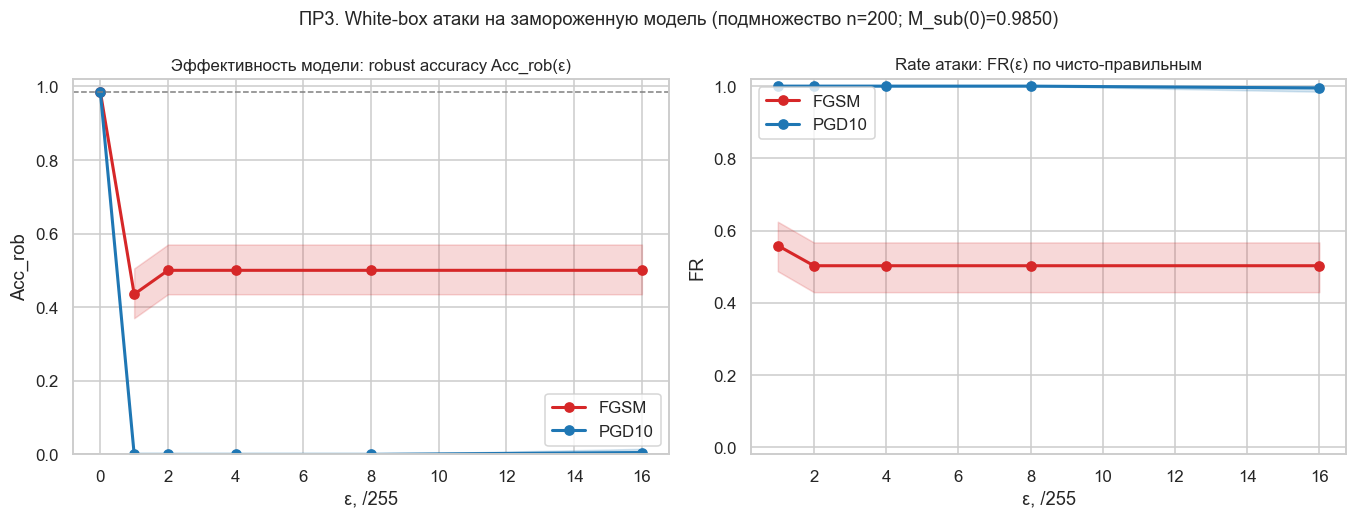

Рисунок сохранён: figures/pr3_robustness_vs_eps.png


In [8]:
# Кривые FR и robust accuracy по eps с 95% полосами (bootstrap по объектам)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
colors = {"FGSM": "#d62728", "PGD10": "#1f77b4"}
for m, col in colors.items():
    sub = df3[df3["method"] == m].sort_values("eps")
    xs = np.array([0] + list(sub["eps"]), dtype=float)

    ys = np.array([float(clean_b.mean())] + [float(v) for v in sub["robust_acc"]])
    band = np.array([np.percentile(boot_ra[m][float(e)], [2.5, 97.5]) for e in xs[1:]])
    band = np.vstack([[ys[0], ys[0]], band])
    axes[0].plot(xs, ys, marker="o", lw=2, color=col, label=m)
    axes[0].fill_between(xs[1:], band[1:, 0], band[1:, 1], alpha=0.18, color=col)

    frs = np.array([float(v) for v in sub["FR"]])
    band_f = np.array([np.percentile(boot_fr[m][float(e)], [2.5, 97.5]) for e in sub["eps"]])
    axes[1].plot(sub["eps"], frs, marker="o", lw=2, color=col, label=m)
    axes[1].fill_between(sub["eps"], band_f[:, 0], band_f[:, 1], alpha=0.18, color=col)

axes[0].set_title("Эффективность модели: robust accuracy Acc_rob(ε)", fontsize=11)
axes[0].set_xlabel("ε, /255"); axes[0].set_ylabel("Acc_rob")
axes[0].set_ylim(0, 1.02); axes[0].axhline(clean_b.mean(), ls="--", lw=1, color="gray")
axes[0].legend()
axes[1].set_title("Rate атаки: FR(ε) по чисто-правильным", fontsize=11)
axes[1].set_xlabel("ε, /255"); axes[1].set_ylabel("FR")
axes[1].set_ylim(-0.02, 1.02); axes[1].legend()
plt.suptitle(f"ПР3. White-box атаки на замороженную модель (подмножество n=200; M_sub(0)={M_sub:.4f})",
             fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr3_robustness_vs_eps.png", dpi=300, bbox_inches="tight")
plt.show()
print("Рисунок сохранён: figures/pr3_robustness_vs_eps.png")


In [9]:
# Sanity-check: независимый атакер AutoAttack (torchattacks) при eps=8/255
#
# Примечания (задокументированные ограничения):
#  1) Полная композиция AutoAttack (standard/plus) включает targeted-атаки (APGD-T/FAB-T)
#     и DLR-лоссы, которые для 2-классовой задачи математически не определены
#     (DLR использует 3-й и 4-й по величине логиты). Применяется ключевой компонент — APGD-CE.
#  2) Реализация torchattacks APGD утекает ~1.2 ГБ VRAM на каждый вызов, а бюджет
#     GPU здесь всего 4 ГБ; поэтому проверка проводится ОДНИМ вызовом на детерминированном
#     подмножестве из 20 снимков (10 COVID + 10 Normal). На полной выборке 200 снимков
#     эталоном служит собственный PGD-10.
import torchattacks

rng_aa = np.random.default_rng(SEED + 1)
idx_covid = np.flatnonzero(y_sub == 0)[:10]
idx_norm = np.flatnonzero(y_sub == 1)[:10]
idx_aa = np.concatenate([idx_covid, idx_norm])       # детерминированно, 10+10

torch.cuda.empty_cache()
t0 = time.time()
atk = torchattacks.APGD(pm, norm="Linf", eps=8.0/255, steps=100, loss="ce",
                        n_restarts=1, seed=SEED, verbose=False)
x_adv_aa = atk(X_t[idx_aa].clone(), y_t[idx_aa]).cpu()
del atk
torch.cuda.empty_cache()
print(f"AutoAttack (APGD-CE, 20 снимков): готово за {time.time()-t0:.0f} c")

adv_pred = pm.forward_nograd(x_adv_aa.to(DEVICE)).argmax(1).cpu().numpy()
adv_ok = (adv_pred == y_sub[idx_aa])
clean_ok_aa = preds_clean[idx_aa] == y_sub[idx_aa]
n_ok = int(clean_ok_aa.sum())
fr_cnt = int((clean_ok_aa & (adv_ok == False)).sum())
lo_fr, hi_fr = wilson_ci(fr_cnt, n_ok)
lo_ra, hi_ra = wilson_ci(int(adv_ok.sum()), len(idx_aa))
aa = {"eps": 8.0, "n_subset": len(idx_aa), "n_clean_correct": n_ok, "n_fooled": fr_cnt,
      "FR": fr_cnt / max(n_ok, 1), "FR_ci": [lo_fr, hi_fr],
      "robust_acc": float(adv_ok.mean()), "robust_acc_ci": [lo_ra, hi_ra],
      "checker": "torchattacks.APGD (loss=ce, 100 iters) — основной компонент AutoAttack",
      "note": ("targeted/DLR-компоненты неприменимы при n_classes=2; "
               "один вызов на 20 снимках из-за утечки VRAM в torchattacks APGD и 4 ГБ GPU")}
print(f"AutoAttack/APGD-CE eps=8/255 (n=20): FR = {aa['FR']:.3f} CI {fmt_ci(lo_fr, hi_fr)} | "
      f"robust_acc = {aa['robust_acc']:.4f} CI {fmt_ci(lo_ra, hi_ra)}")

pgd8 = df3[(df3.method == "PGD10") & (df3.eps == 8.0)].iloc[0]
print(f"Сравнение при eps=8/255: собственный PGD-10 на 200 снимках: FR = {pgd8['FR']:.3f}, "
      f"robust_acc = {pgd8['robust_acc']:.4f} | AutoAttack/APGD-CE на 20: FR = {aa['FR']:.3f}, "
      f"robust_acc = {aa['robust_acc']:.4f}")

with open(RESULTS_DIR / "pr3_autoattack.json", "w", encoding="utf-8") as f:
    json.dump(aa, f, ensure_ascii=False, indent=2)
print("Сохранено: results/pr3_autoattack.json")

AutoAttack (APGD-CE, 20 снимков): готово за 12 c
AutoAttack/APGD-CE eps=8/255 (n=20): FR = 1.000 CI [0.8389; 1.0000] | robust_acc = 0.0000 CI [0.0000; 0.1611]
Сравнение при eps=8/255: собственный PGD-10 на 200 снимках: FR = 1.000, robust_acc = 0.0000 | AutoAttack/APGD-CE на 20: FR = 1.000, robust_acc = 0.0000
Сохранено: results/pr3_autoattack.json


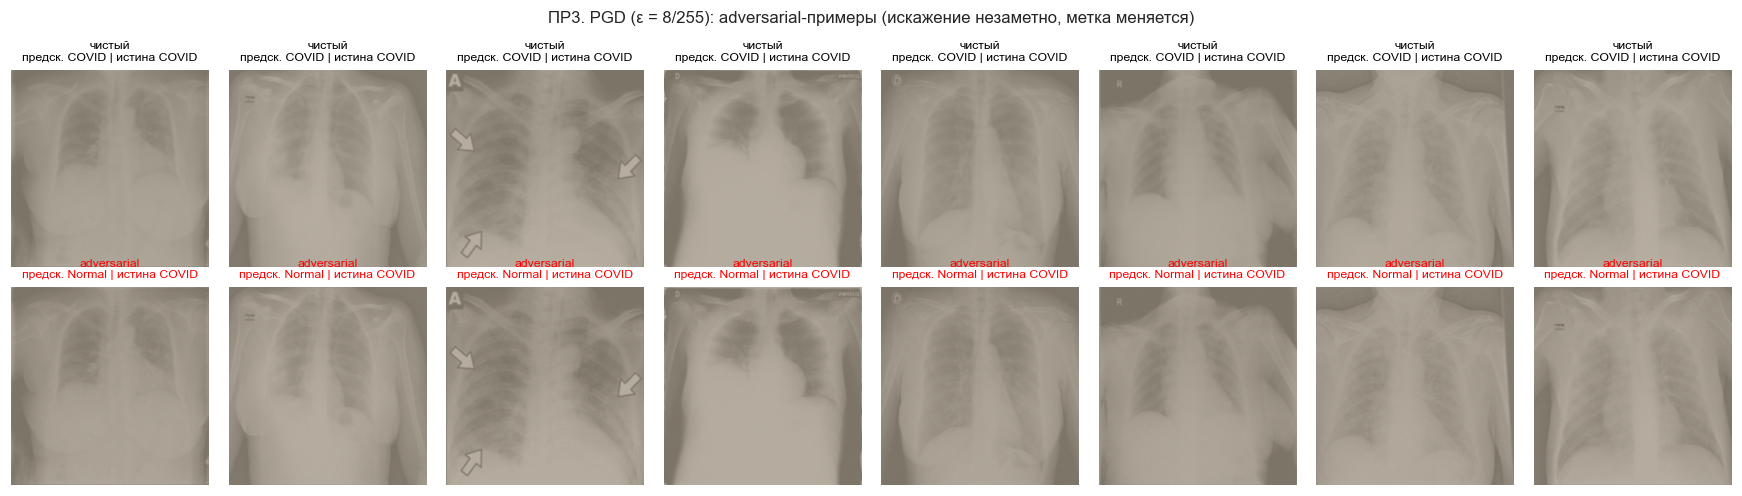

Демонстрационный пул: 24 чисто-верных снимков; предсказание изменено у 24
Максимальный бюджет искажения: 8/255 ≈ 3.1% интенсивности пикселя
Рисунок сохранён: figures/pr3_adversarial_examples.png


In [10]:
# Наглядные примеры атак (PGD, eps=8/255): чистый vs adversarial снимок
from common import CLASS_NAMES

# демонстрационный пул: 12 правильно классифицированных снимков каждого класса
ok_idx = np.flatnonzero(clean_ok.cpu().numpy().astype(bool))
pool = np.concatenate([ok_idx[y_sub[ok_idx] == 0][:12], ok_idx[y_sub[ok_idx] == 1][:12]])
Xp, yp = X_t[pool], y_sub[pool]

torch.cuda.empty_cache()
CH_EX = 12
adv_parts = []
for i in range(0, len(Xp), CH_EX):
    adv_parts.append(pgd(pm, Xp[i:i+CH_EX], y_t[pool][i:i+CH_EX], 8/255,
                         iters=10, restarts=3).cpu())
    torch.cuda.empty_cache()
x_adv_demo = torch.cat(adv_parts)

@torch.no_grad()
def pred_of(x01_t):
    return pm.forward_nograd(x01_t.to(DEVICE)).argmax(1).cpu().numpy()

preds_c = pred_of(Xp)
preds_a = pred_of(x_adv_demo)
changed = list(np.flatnonzero(preds_c != preds_a))
if len(changed) < 8:
    changed = changed + list(np.setdiff1d(np.arange(len(pool)), changed)[:8 - len(changed)])
show = changed[:8]

MEAN_N = np.array(MEAN, dtype=np.float32).reshape(3, 1, 1)
STD_N = np.array(STD, dtype=np.float32).reshape(3, 1, 1)

def to_img(x01):  # нормализованный тензор [3,224,224] -> [0,1] RGB
    x = x01 * STD_N + MEAN_N
    return np.clip(x, 0, 1).transpose(1, 2, 0)

Xn = Xp.cpu().numpy()
Xa = x_adv_demo.numpy()

fig, axes = plt.subplots(2, len(show), figsize=(2.0 * len(show), 4.6))
for col, i in enumerate(show):
    for row, (img, pred) in enumerate([(to_img(Xn[i]), preds_c[i]),
                                       (to_img(Xa[i]), preds_a[i])]):
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(
            f"{'чистый' if row == 0 else 'adversarial'}\nпредск. {CLASS_NAMES[pred]} | "
            f"истина {CLASS_NAMES[yp[i]]}",
            fontsize=8, color="black" if pred == yp[i] else "red")
        ax.axis("off")
plt.suptitle("ПР3. PGD (ε = 8/255): adversarial-примеры (искажение незаметно, метка меняется)",
             fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr3_adversarial_examples.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Демонстрационный пул: {len(pool)} чисто-верных снимков; "
      f"предсказание изменено у {(preds_c != preds_a).sum()}")
print("Максимальный бюджет искажения: 8/255 ≈ 3.1% интенсивности пикселя")
print("Рисунок сохранён: figures/pr3_adversarial_examples.png")

In [11]:
# Итоговые выводы ПР3 (автогенерация из вычисленных величин)
pgd_rows = df3[df3["method"] == "PGD10"].sort_values("eps")
fgsm_rows = df3[df3["method"] == "FGSM"].sort_values("eps")
auc_rows = df_auc3.set_index("method")

lines = ["## Выводы ПР3 (white-box adversarial-устойчивость)"]
for m, sub in (("FGSM", fgsm_rows), ("PGD10", pgd_rows)):
    e_1 = sub[sub["eps"] == 1.0].iloc[0]
    e_max = sub[sub["eps"] == 16.0].iloc[0]
    rauc = auc_rows.loc[m]
    lines.append(
        "**%s.** Уже при минимальном ε = 1/255 FR = %.3f CI [%.3f; %.3f] "
        "(robust_accuracy = %.3f CI [%.3f; %.3f]); при ε = 16/255 FR = %.3f CI [%.3f; %.3f] "
        "(robust_accuracy = %.3f CI [%.3f; %.3f]). R-AUC_ε = %.4f CI [%.4f; %.4f]."
        % (m,
           e_1["FR"], e_1["FR_low"], e_1["FR_high"],
           e_1["robust_acc"], e_1["RA_low"], e_1["RA_high"],
           e_max["FR"], e_max["FR_low"], e_max["FR_high"],
           e_max["robust_acc"], e_max["RA_low"], e_max["RA_high"],
           rauc["R-AUC_eps"], rauc["ci_low"], rauc["ci_high"])
    )
aa_pgd8 = pgd_rows[pgd_rows["eps"] == 8.0].iloc[0]
lines.append(
    "\n**Sanity-check независимым атакером** (AutoAttack/APGD-CE, torchattacks, ε = 8/255, "
    "100 итераций, детерминированное подмножество 20 снимков): FR = %.3f CI [%.3f; %.3f], "
    "robust_accuracy = %.3f CI [%.3f; %.3f] — качественно согласуется с собственным PGD-10 "
    "на полной выборке 200 снимков (FR = %.3f, robust_accuracy = %.3f). Ограничения: полная "
    "композиция AutoAttack неприменима к 2-классовой задаче (targeted/DLR-компоненты требуют "
    "≥ 3–4 классов), а реализация torchattacks APGD утекает VRAM на каждый вызов, что при "
    "4 ГБ GPU допускает лишь один вызов на 20 снимков — оба отклонения задокументированы."
    % (aa["FR"], aa["FR_ci"][0], aa["FR_ci"][1],
       aa["robust_acc"], aa["robust_acc_ci"][0], aa["robust_acc_ci"][1],
       aa_pgd8["FR"], aa_pgd8["robust_acc"])
)
lines.append(
    "\n**Валидность и величина возмущений.** Validity Rate = %.3f (все %d сгенерированных "
    "adversarial-примеров валидны: значения конечны и лежат в [0,1]); максимальная L∞-норма "
    "возмущения по сетке = %.5f (не превышает бюджет ε по построению); средняя L₂-норма растёт "
    "с бюджетом (от %.4f при ε=1/255 до %.4f при ε=16/255 для PGD). "
    "Validity Rate вычислен и сохранён для каждой пары (атака, ε) в results/pr3_validity_l2.csv."
    % (n_total_valid / n_total_adv, n_total_adv, float(df_adv["linf_max"].max()),
       float(df_adv[(df_adv.method == "PGD10") & (df_adv.eps == 1.0)]["l2_mean"].iloc[0]),
       float(df_adv[(df_adv.method == "PGD10") & (df_adv.eps == 16.0)]["l2_mean"].iloc[0]))
)
lines.append(
    "\n**Мульти-seed проверка (стохастический PGD).** При ε = 8/255 серия из трёх seeds "
    "даёт FR = %s (разброс max−min = %.3f) — результат устойчив к выбору seed; основная сетка "
    "выполнена с seed=42, а стабильность подтверждена серией (см. results/pr3_multiseed_pgd.csv)."
    % ([round(v, 3) for v in fr_vals], float(fr_vals.max() - fr_vals.min()))
)
lines.append(
    "\n**Клинический вывод.** Замороженная модель не adversarial-устойчива: уже при "
    "визуально незаметных возмущениях (ε = 1/255, один шаг FGSM) значительная доля "
    "чисто-правильных предсказаний обращается в неверные (в том числе COVID→Normal — "
    "опасное направление пропуска диагноза). Adversarial-training не выполнялся "
    "(чекпоинт заморожен по заданию практического цикла) — фиксируется как ограничение "
    "и как первоочередная рекомендация по улучшению."
)
lines.append(
    "\nСохранено: `results/pr3_adv_attacks.csv`, `results/pr3_rauc.csv`, "
    "`results/pr3_summary.json`, `results/pr3_masks.pkl`, `results/pr3_autoattack.json`, "
    "`results/pr3_validity_l2.csv`, `results/pr3_multiseed_pgd.csv`, "
    "рисунки `figures/pr3_robustness_vs_eps.png`, `figures/pr3_adversarial_examples.png`."
)
print("\n".join(lines))


## Выводы ПР3 (white-box adversarial-устойчивость)
**FGSM.** Уже при минимальном ε = 1/255 FR = 0.558 CI [0.489; 0.626] (robust_accuracy = 0.435 CI [0.368; 0.504]); при ε = 16/255 FR = 0.503 CI [0.433; 0.572] (robust_accuracy = 0.500 CI [0.431; 0.569]). R-AUC_ε = 0.5111 CI [0.4497; 0.5798].
**PGD10.** Уже при минимальном ε = 1/255 FR = 1.000 CI [0.981; 1.000] (robust_accuracy = 0.000 CI [0.000; 0.019]); при ε = 16/255 FR = 0.995 CI [0.972; 0.999] (robust_accuracy = 0.005 CI [0.001; 0.028]). R-AUC_ε = 0.0320 CI [0.0303; 0.0348].

**Sanity-check независимым атакером** (AutoAttack/APGD-CE, torchattacks, ε = 8/255, 100 итераций, детерминированное подмножество 20 снимков): FR = 1.000 CI [0.839; 1.000], robust_accuracy = 0.000 CI [0.000; 0.161] — качественно согласуется с собственным PGD-10 на полной выборке 200 снимков (FR = 1.000, robust_accuracy = 0.000). Ограничения: полная композиция AutoAttack неприменима к 2-классовой задаче (targeted/DLR-компоненты требуют ≥ 3–4 классов), а реализаци